# 1. Tổng quan dữ liệu

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("../data/creditcard.csv")
print(df.shape)
print("Gia tri thieu:", df.isnull().sum().sum())
print(df["Class"].value_counts())
print((df["Class"].value_counts(normalize=True) * 100).round(3))
df.head()

(284807, 31)
Gia tri thieu: 0
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    99.827
1     0.173
Name: proportion, dtype: float64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


# 2. Phân tích mất cân bằng

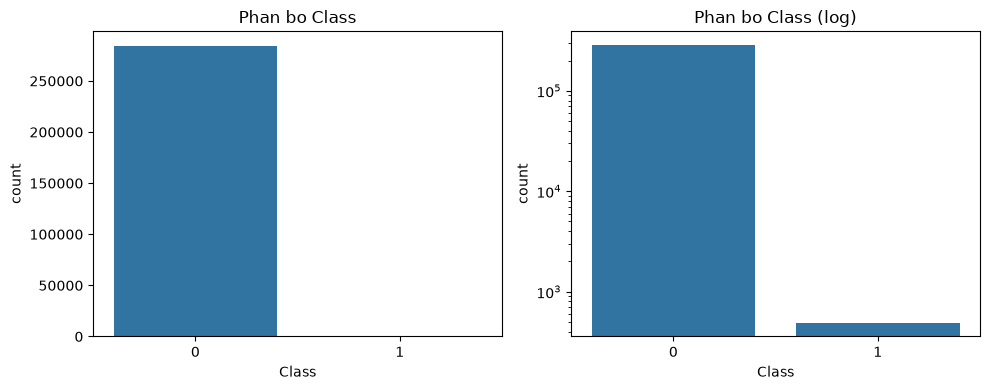

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Class", data=df, ax=ax[0]); ax[0].set_title("Phan bo Class")
sns.countplot(x="Class", data=df, ax=ax[1]); ax[1].set_yscale("log"); ax[1].set_title("Phan bo Class (log)")
plt.tight_layout(); plt.show()

# 3. Phân bố Amount và Time

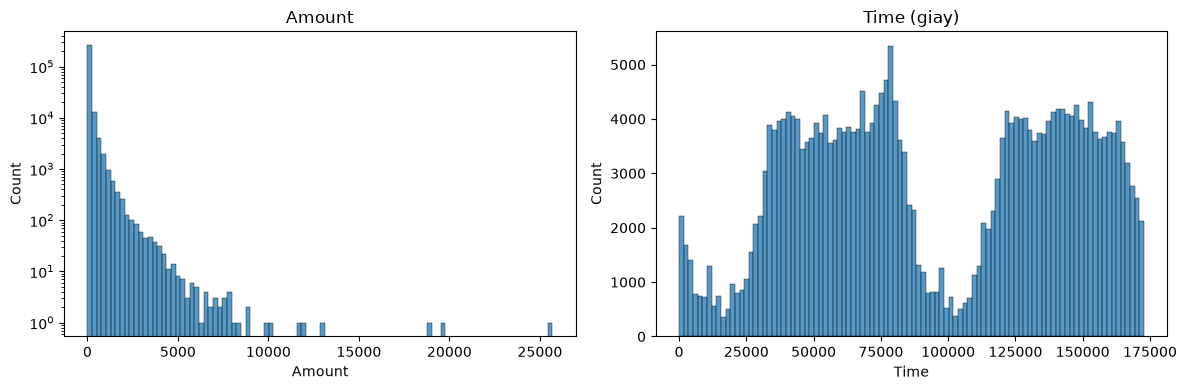

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Amount"], bins=100, ax=ax[0]); ax[0].set_yscale("log"); ax[0].set_title("Amount")
sns.histplot(df["Time"], bins=100, ax=ax[1]); ax[1].set_title("Time (giay)")
plt.tight_layout(); plt.show()

# 4. Tương quan

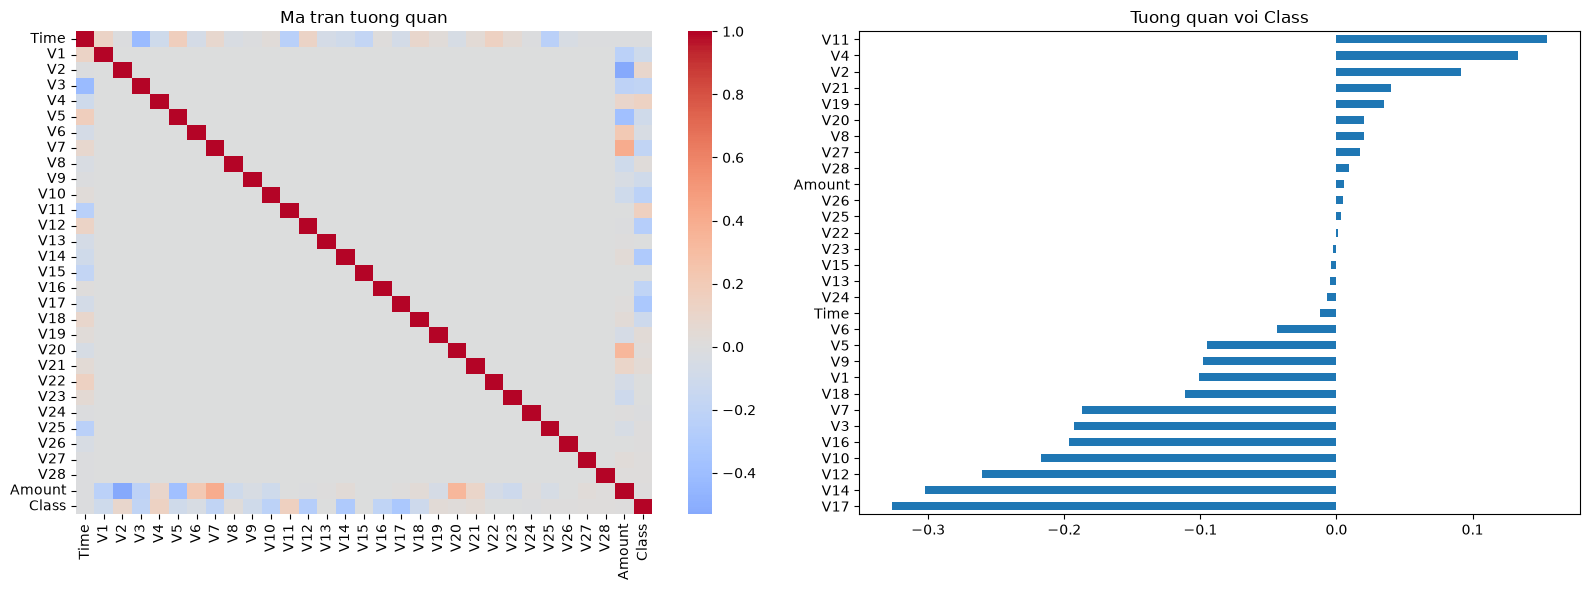

In [4]:
corr = df.corr()
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax[0]); ax[0].set_title("Ma tran tuong quan")
corr["Class"].drop("Class").sort_values().plot(kind="barh", ax=ax[1]); ax[1].set_title("Tuong quan voi Class")
plt.tight_layout(); plt.show()

# 5. Outlier

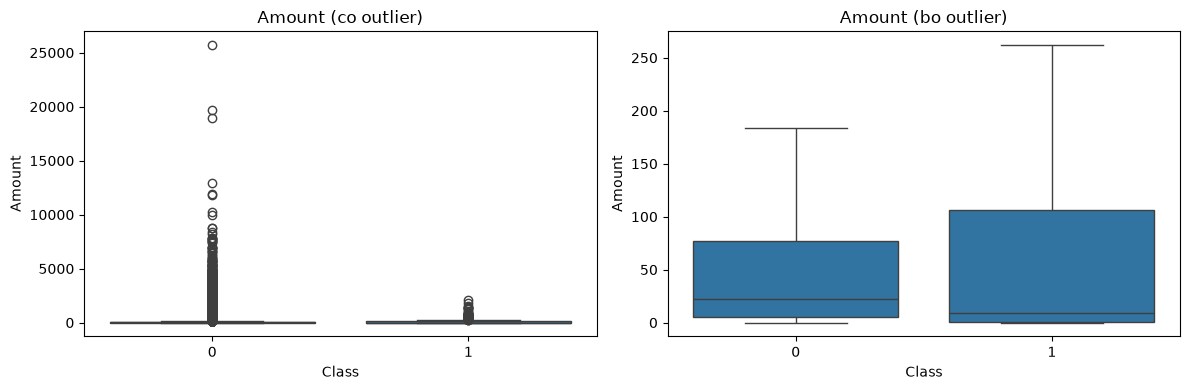

So outlier Amount (IQR): 31904


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="Class", y="Amount", data=df, ax=ax[0]); ax[0].set_title("Amount (co outlier)")
sns.boxplot(x="Class", y="Amount", data=df, showfliers=False, ax=ax[1]); ax[1].set_title("Amount (bo outlier)")
plt.tight_layout(); plt.show()

q1, q3 = df["Amount"].quantile([0.25, 0.75]); iqr = q3 - q1
n_out = ((df["Amount"] < q1 - 1.5*iqr) | (df["Amount"] > q3 + 1.5*iqr)).sum()
print("So outlier Amount (IQR):", n_out)

# 6. Chia dữ liệu, scale, SMOTE

Train: {0: 227451, 1: 394} | Test: {0: 56864, 1: 98}
Sau SMOTE: {0: 227451, 1: 227451}


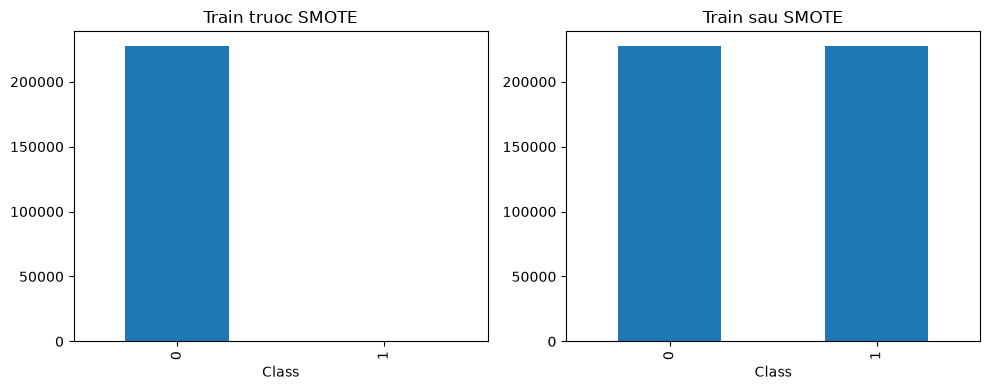

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from imblearn.over_sampling import SMOTE

X = df.drop(columns="Class"); y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# scale: chi fit tren train
X_train, X_test = X_train.copy(), X_test.copy()
cols = ["Amount", "Time"]
scaler = RobustScaler().fit(X_train[cols])
X_train[cols] = scaler.transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

print("Train:", y_train.value_counts().to_dict(), "| Test:", y_test.value_counts().to_dict())

# SMOTE: CHI tren tap train
X_res, y_res = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("Sau SMOTE:", y_res.value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().plot(kind="bar", ax=ax[0], title="Train truoc SMOTE")
y_res.value_counts().plot(kind="bar", ax=ax[1], title="Train sau SMOTE")
plt.tight_layout(); plt.show()

# 7. Đo thời gian train Local

In [7]:
import time, platform, os, psutil
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import recall_score, average_precision_score

print("CPU:", platform.processor(), "| So luong:", os.cpu_count())
print("RAM:", round(psutil.virtual_memory().total / 1e9, 1), "GB")

models = {
    "RandomForest": lambda: RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
    "LightGBM": lambda: LGBMClassifier(n_estimators=200, learning_rate=0.1, random_state=42, verbose=-1),
}

results = []
for name, make in models.items():
    times = []
    for _ in range(3):
        m = make(); t0 = time.time(); m.fit(X_res, y_res); times.append(time.time() - t0)
    proba = m.predict_proba(X_test)[:, 1]
    results.append({"Model": name, "Thoi gian TB (s)": round(np.mean(times), 1),
                    "Recall@0.5": round(recall_score(y_test, proba > 0.5), 3),
                    "PR-AUC": round(average_precision_score(y_test, proba), 3)})
pd.DataFrame(results)

CPU: Intel64 Family 6 Model 186 Stepping 3, GenuineIntel | So luong: 12
RAM: 16.8 GB


,Model,Thoi gian TB (s),Recall@0.5,PR-AUC
0,RandomForest,55.1,0.857,0.825
1,LightGBM,5.9,0.837,0.775
